In [15]:
# ── Configuration ──────────────────────────────────────────────────────────
# Edit DATA_PATH to point to your CSV file.
# All other paths are derived automatically.
from pathlib import Path

DATA_PATH = Path("archive/spotify-tracks-dataset.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at '{DATA_PATH.resolve()}'.\n"
        "Update DATA_PATH above to point to the correct location."
    )

print("Dataset path:", DATA_PATH.resolve())

Dataset path: D:\entc_ml_project-master\entc_ml_project-master\archive\spotify-tracks-dataset.csv


In [16]:
# ── Imports ────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

In [17]:
# ── Load dataset ───────────────────────────────────────────────────────────
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape}")
df.head()

Shape: (114000, 22)


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [18]:
# ── Column overview ────────────────────────────────────────────────────────
print("Columns:")
print(list(df.columns))

Columns:
['Unnamed: 0.1', 'Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


In [19]:
# ── Drop artefact index columns ────────────────────────────────────────────
unnamed_cols = [c for c in df.columns if c.startswith("Unnamed")]
df.drop(columns=unnamed_cols, inplace=True)
print(f"Dropped {len(unnamed_cols)} unnamed column(s): {unnamed_cols}")
print(f"Shape after drop: {df.shape}")

Dropped 2 unnamed column(s): ['Unnamed: 0.1', 'Unnamed: 0']
Shape after drop: (114000, 20)


In [20]:
# ── Null value analysis ────────────────────────────────────────────────────
null_counts = df.isnull().sum()
print(f"Total nulls: {null_counts.sum()}")
print(null_counts[null_counts > 0] if null_counts.sum() > 0 else "No nulls found.")

null_pct = (null_counts / len(df) * 100).round(2)
print("\nNull % per column:")
print(null_pct[null_pct > 0] if null_pct.sum() > 0 else "None.")

Total nulls: 3
artists       1
album_name    1
track_name    1
dtype: int64

Null % per column:
None.


In [21]:
# ── Drop nulls and duplicates ──────────────────────────────────────────────
before = len(df)
df.dropna(inplace=True)
print(f"Dropped {before - len(df)} rows with nulls.")

before = len(df)
df.drop_duplicates(inplace=True)
print(f"Dropped {before - len(df)} duplicate rows.")
print(f"Shape after cleaning: {df.shape}")

Dropped 1 rows with nulls.
Dropped 450 duplicate rows.
Shape after cleaning: (113549, 20)


In [22]:
# ── Drop non-numeric identifier columns ────────────────────────────────────
text_cols = ["track_id", "artists", "album_name", "track_name"]
existing  = [c for c in text_cols if c in df.columns]
df.drop(columns=existing, inplace=True)
print(f"Dropped text columns: {existing}")
print(f"Shape: {df.shape}")
df.head()

Dropped text columns: ['track_id', 'artists', 'album_name', 'track_name']
Shape: (113549, 16)


,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [23]:
# ── Remove rows with physically impossible values ──────────────────────────
broken_mask = (
    (df["duration_ms"]    <= 0)
    | (df["tempo"]         <= 0)
    | (df["loudness"]      > 0)
    | (df["time_signature"] < 3)
)
before = len(df)
df = df.loc[~broken_mask].copy()
print(f"Removed {before - len(df)} rows with invalid values.")
print(f"Final shape: {df.shape}")

Removed 1220 rows with invalid values.
Final shape: (112329, 16)


In [24]:
# ── Final dataset info ─────────────────────────────────────────────────────
df.info()
print("\nBasic statistics:")
df.describe().round(3)

<class 'pandas.DataFrame'>
Index: 112329 entries, 0 to 113999
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   popularity        112329 non-null  int64  
 1   duration_ms       112329 non-null  int64  
 2   explicit          112329 non-null  bool   
 3   danceability      112329 non-null  float64
 4   energy            112329 non-null  float64
 5   key               112329 non-null  int64  
 6   loudness          112329 non-null  float64
 7   mode              112329 non-null  int64  
 8   speechiness       112329 non-null  float64
 9   acousticness      112329 non-null  float64
 10  instrumentalness  112329 non-null  float64
 11  liveness          112329 non-null  float64
 12  valence           112329 non-null  float64
 13  tempo             112329 non-null  float64
 14  time_signature    112329 non-null  int64  
 15  track_genre       112329 non-null  str    
dtypes: bool(1), float64(9), int64(5), st

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000
mean,33.354,228342.412,0.569,0.644,5.313,-8.191,0.638,0.084,0.312,0.154,0.213,0.476,122.451,3.935
std,22.315,105115.485,0.172,0.249,3.561,4.923,0.481,0.104,0.330,0.307,0.190,0.259,29.618,0.305
min,0.000,15800.000,0.051,0.000,0.000,-46.591,0.000,0.022,0.000,0.000,0.009,0.000,30.200,3.000
25%,17.000,174649.000,0.458,0.476,2.000,-9.940,0.000,0.036,0.017,0.000,0.098,0.262,99.762,4.000
50%,35.000,213200.000,0.582,0.687,5.000,-6.972,1.000,0.049,0.166,0.000,0.132,0.466,122.058,4.000
75%,50.000,261720.000,0.695,0.854,8.000,-4.994,1.000,0.084,0.589,0.045,0.273,0.684,140.105,4.000
max,100.000,5237295.000,0.985,1.000,11.000,-0.001,1.000,0.965,0.996,1.000,1.000,0.995,243.372,5.000


Unique genres: 114


C:\Users\abhij\AppData\Local\Temp\ipykernel_7672\162410046.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genres.index, y=top_genres.values, palette="viridis", ax=ax)


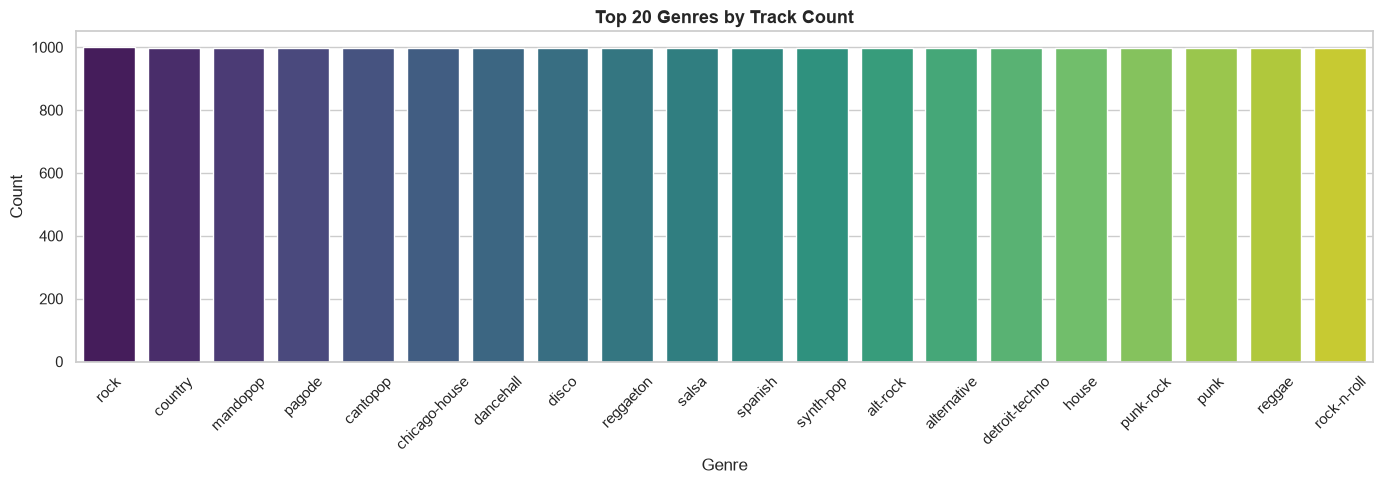

In [25]:
# ── Genre distribution ─────────────────────────────────────────────────────
print(f"Unique genres: {df['track_genre'].nunique()}")
top_genres = df["track_genre"].value_counts().head(20)

fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(x=top_genres.index, y=top_genres.values, palette="viridis", ax=ax)
ax.set_title("Top 20 Genres by Track Count", fontsize=13, fontweight="bold")
ax.set_xlabel("Genre")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

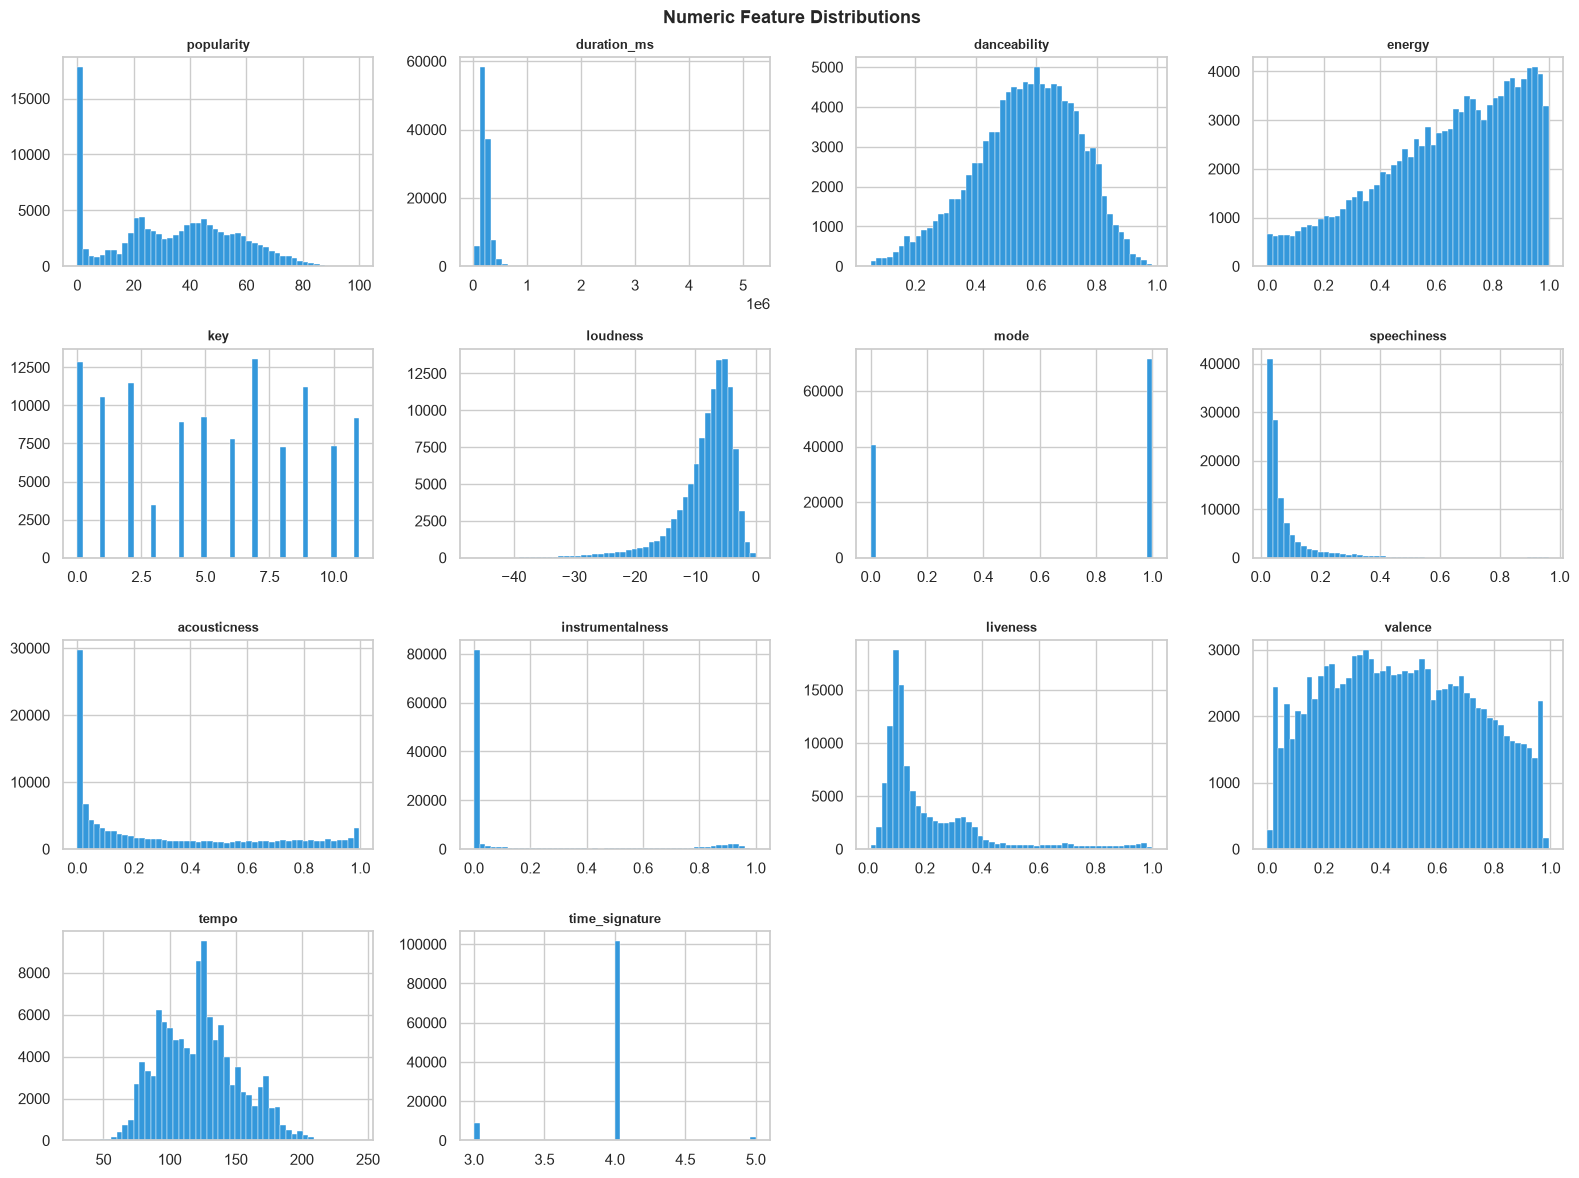

In [26]:
# ── Numeric feature distributions ─────────────────────────────────────────
numeric_cols = df.select_dtypes(include="number").columns.tolist()

n_cols = 4
n_rows = -(-len(numeric_cols) // n_cols)  # ceiling division
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col].dropna(), bins=50, color="#3498db",
                 edgecolor="white", linewidth=0.3)
    axes[i].set_title(col, fontsize=9, fontweight="bold")
    axes[i].set_xlabel("")

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Numeric Feature Distributions", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

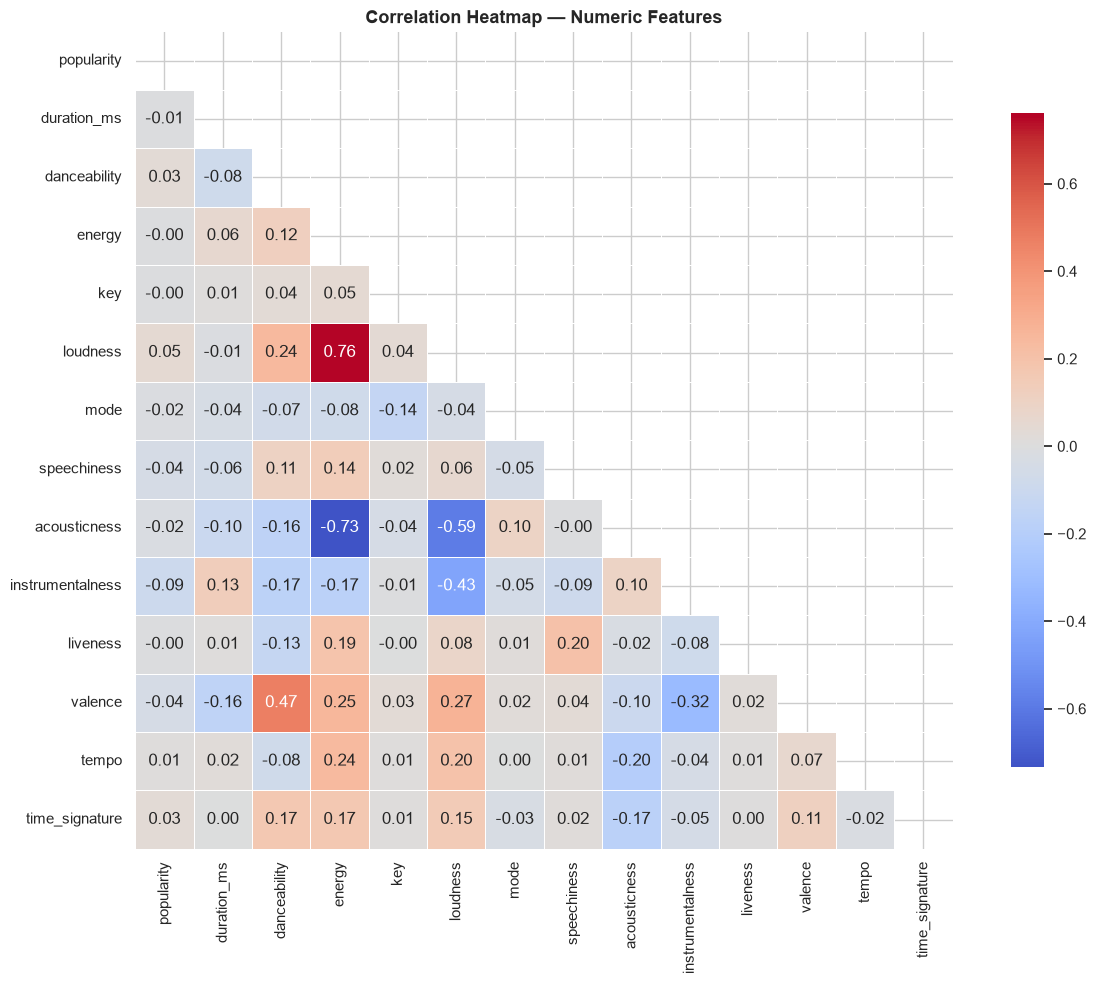

In [27]:
# ── Correlation heatmap ────────────────────────────────────────────────────
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, linewidths=0.5, square=True, cbar_kws={"shrink": 0.8}, ax=ax
)
ax.set_title("Correlation Heatmap — Numeric Features", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

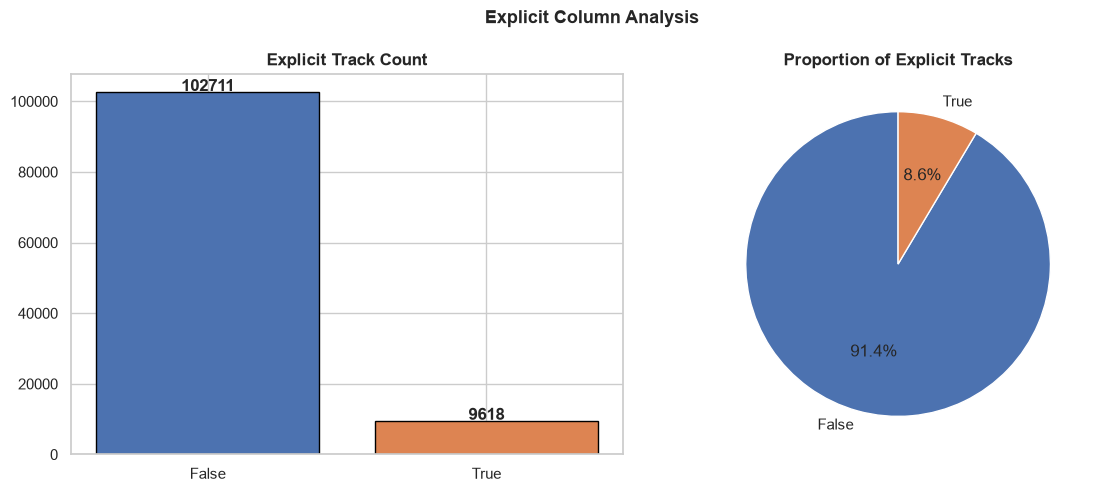

In [28]:
# ── Explicit track breakdown ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
counts = df["explicit"].value_counts()

axes[0].bar(counts.index.astype(str), counts.values,
            color=["#4C72B0", "#DD8452"], edgecolor="black")
axes[0].set_title("Explicit Track Count", fontweight="bold")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 200, str(v), ha="center", fontweight="bold")

axes[1].pie(counts.values, labels=counts.index.astype(str), autopct="%1.1f%%",
            colors=["#4C72B0", "#DD8452"], startangle=90)
axes[1].set_title("Proportion of Explicit Tracks", fontweight="bold")

plt.suptitle("Explicit Column Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()